# 03 - Red neuronal convolucional (CNN)

Muestra la CNN en Keras que clasifica cada rostro como **real (0)** o **ataque (1)**. El modelo está en
`src/models/cnn.py`, sigue el estilo del Colab de clase `P2_Convnets_KERAS` (`Sequential`, `compile`, `fit`)
y se entrena como los otros modelos:

```
python -m src.train --modelo cnn
python -m src.train --modelo cnn --fuente_test lcc_eval
```

Este notebook solo llama a ese código y muestra los resultados. Funciona en **Google Colab** y en local.

## 1. Preparación

Detecta si corre en Colab o en local. En Colab monta Drive, clona el repositorio y copia las matrices
`lcc_64_rgb` y `lcc_eval_64_rgb_norm-lcc`; en local usa la raíz del repositorio.

In [1]:
import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Alous12/Proyecto_IA.git"
DRIVE_MATRICES = "/content/drive/MyDrive/Proyecto_IA/matrices"
CARPETAS = ["lcc_64_rgb", "lcc_eval_64_rgb_norm-lcc"]

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not Path("/content/Proyecto_IA").exists():
        !git clone -q {REPO_URL} /content/Proyecto_IA
    RAIZ = Path("/content/Proyecto_IA")
    for carpeta in CARPETAS:
        destino = RAIZ / "data/processed/matrices" / carpeta
        destino.mkdir(parents=True, exist_ok=True)
        !cp -n {DRIVE_MATRICES}/{carpeta}/*.npz {destino}/
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: C:\Users\alemv\Documents\Inteligencia Artificial\Proyecto_Grupal_IA


## 2. Datos

`cargar_datos(..., color="rgb")` entrega cada rostro aplanado (64·64·3 = 12,288 valores normalizados).
La CNN lo reordena a `(N, 64, 64, 3)`, la forma que espera Keras. Para mostrar algunas imágenes se deshace la
normalización con la media y la desviación guardadas en `normalizacion.npz`.

train X (8694, 64, 64, 3)  reales 1124  ataques 7570


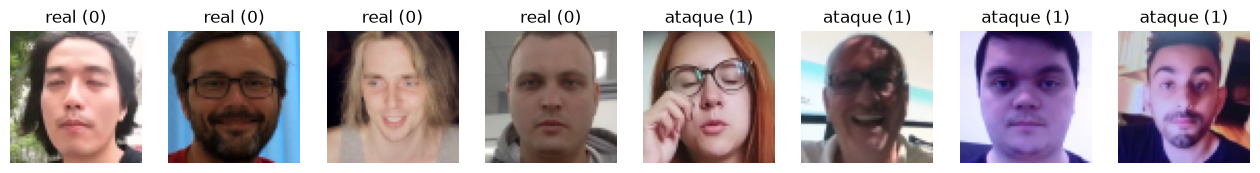

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Image, display

from src import config
from src.data.dataset import cargar_datos
from src.evaluate import imprimir_resumen
from src.models import cnn

%matplotlib inline
# (src.evaluate cambia matplotlib a "Agg" para guardar PNG; la línea de arriba vuelve a mostrar gráficas aquí)

X_train, y_train, info_train = cargar_datos("train", fuente="lcc", color="rgb")
X_train = cnn.a_imagenes(X_train)   # X.reshape(-1, 64, 64, 3)
print(f"train X {X_train.shape}  reales {(y_train == 0).sum()}  ataques {(y_train == 1).sum()}")

normalizacion = np.load(config.DIR_MATRICES / "lcc_64_rgb" / "normalizacion.npz")
media = normalizacion["media"].reshape(64, 64, 3)
desviacion = normalizacion["desviacion"].reshape(64, 64, 3)

rng = np.random.default_rng(42)
indices = np.concatenate([rng.choice(np.where(y_train == 0)[0], 4, replace=False),
                          rng.choice(np.where(y_train == 1)[0], 4, replace=False)])
fig, ejes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, i in zip(ejes, indices):
    ax.imshow(np.clip(X_train[i] * desviacion + media, 0, 1))
    ax.set_title("real (0)" if y_train[i] == 0 else "ataque (1)")
    ax.axis("off")
plt.show()

## 3. Modelo

`cnn.construir_cnn()` es una adaptación directa de la red del Colab de MNIST: entrada de 64×64×3, dos capas
de *max pooling* (como en VGG-16) para reducir el tamaño, *dropout* antes de la salida y una sola neurona
sigmoide que da la probabilidad de ataque. Se compila con Adam (0.001) y la entropía cruzada binaria.

Dimensiones con la fórmula de la clase, $n_{out} = \left\lfloor \dfrac{n + 2p - f}{s} \right\rfloor + 1$:

| Capa | Operación | Cálculo | Salida |
|---|---|---|---|
| Entrada | | | 64 × 64 × 3 |
| Conv2D 32, f=3, s=2, `same` (p=1) | convolución | ⌊(64 + 2 − 3) / 2⌋ + 1 = 32 | 32 × 32 × 32 |
| Conv2D 32, f=3, s=1, `valid` (p=0) | convolución | (32 − 3) / 1 + 1 = 30 | 30 × 30 × 32 |
| MaxPooling2D f=2, s=2 | max pooling | (30 − 2) / 2 + 1 = 15 | 15 × 15 × 32 |
| Conv2D 32, f=3, s=1, `valid` | convolución | (15 − 3) / 1 + 1 = 13 | 13 × 13 × 32 |
| MaxPooling2D f=2, s=2 | max pooling | ⌊(13 − 2) / 2⌋ + 1 = 6 | 6 × 6 × 32 |
| Flatten | | 6 · 6 · 32 | 1,152 |
| Dense 128, ReLU + Dropout 0.3 | | | 128 |
| Dense 1, sigmoide | | | 1 |

In [3]:
model = cnn.construir_cnn()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 30, 30, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 13, 13, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,105 (652.75 KB)

 Trainable params: 167,105 (652.75 KB)

 Non-trainable params: 0 (0.00 B)

Diagrama de la red con `plot_model`. Necesita `pydot` y Graphviz (vienen en Colab); si no están
instalados en local, se salta con un mensaje.

In [4]:
try:
    imagen = tf.keras.utils.plot_model(model, show_shapes=True)
    if imagen is not None:
        display(imagen)
except Exception as error:
    print("No se pudo dibujar el modelo (falta pydot/Graphviz):", error)

No se pudo dibujar el modelo (falta pydot/Graphviz): You must install pydot (`pip install pydot`) for `plot_model` to work.


## 4. Entrenamiento

`python -m src.train --modelo cnn` entrena con `model.fit` (20 épocas, lotes de 128). `class_weight`
multiplica el error de cada imagen real por $n_{ataques}/n_{reales}$ ≈ 6.73 para compensar el desbalance, y
*EarlyStopping* detiene el entrenamiento si `val_loss` no mejora en 5 épocas y recupera los pesos de la mejor.
Aquí solo se leen los resultados que dejó en `results/cnn_64_rgb/`.

In [5]:
NOMBRE, NOMBRE_EVAL = "cnn_64_rgb", "cnn_64_rgb_test-lcc_eval"
DIR_CNN, DIR_EVAL = config.DIR_RESULTS / NOMBRE, config.DIR_RESULTS / NOMBRE_EVAL

with open(DIR_CNN / "hiperparametros.json", encoding="utf-8") as f:
    resumen = json.load(f)["resumen"]
print(f"peso de la clase real = {resumen['peso_real']:.2f}")
print(f"épocas corridas = {resumen['epocas_corridas']}, mejor época = {resumen['mejor_epoca']}")
print(f"val ACER = {resumen['val_acer']:.3f}, val AUC = {resumen['val_auc']:.3f}")

peso de la clase real = 6.73
épocas corridas = 7, mejor época = 2
val ACER = 0.330, val AUC = 0.760


## 5. Curva de error

Pérdida de train y de validación por época (`history.history['loss']` y `['val_loss']`, como en el Colab de
clase). La de train incluye el peso de las clases y la de validación no, por eso no están en la misma escala.

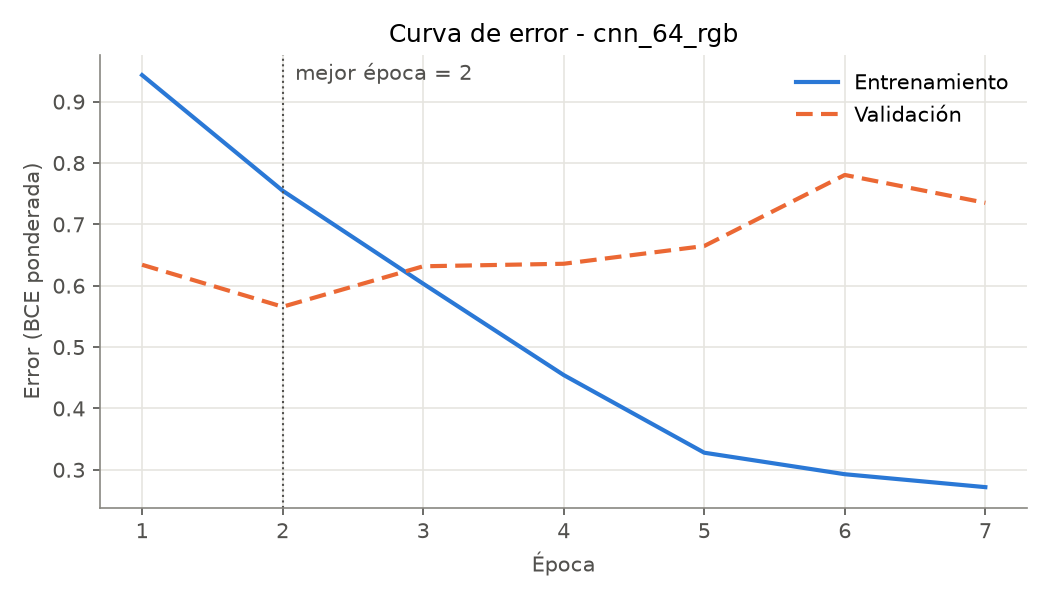

In [6]:
display(Image(DIR_CNN / "curva_error.png", width=600))

## 6. Evaluación en test (LCC FASD)

`evaluar_modelo` elige el umbral en val (APCER = BPCER) y calcula APCER, BPCER, ACER y AUC en test, por frame y
por video, igual que para la regresión logística y la red feed-forward.


=== cnn_64_rgb  (val: lcc, test: lcc) ===
por_frame  umbral=0.507  APCER=0.275  BPCER=0.259  ACER=0.267  exactitud=0.727  AUC=0.825  APCER por tipo={'spoof': 0.275}
por_video  umbral=0.505  APCER=0.228  BPCER=0.259  ACER=0.244  exactitud=0.767  AUC=0.833  APCER por tipo={'spoof': 0.228}


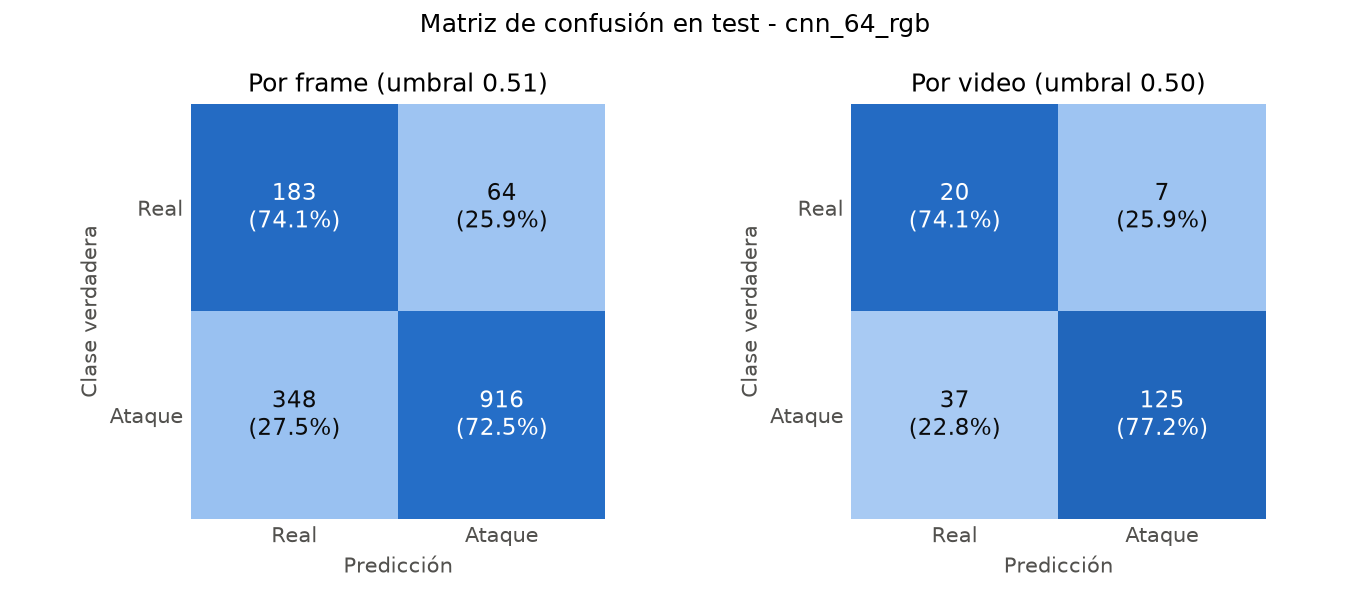

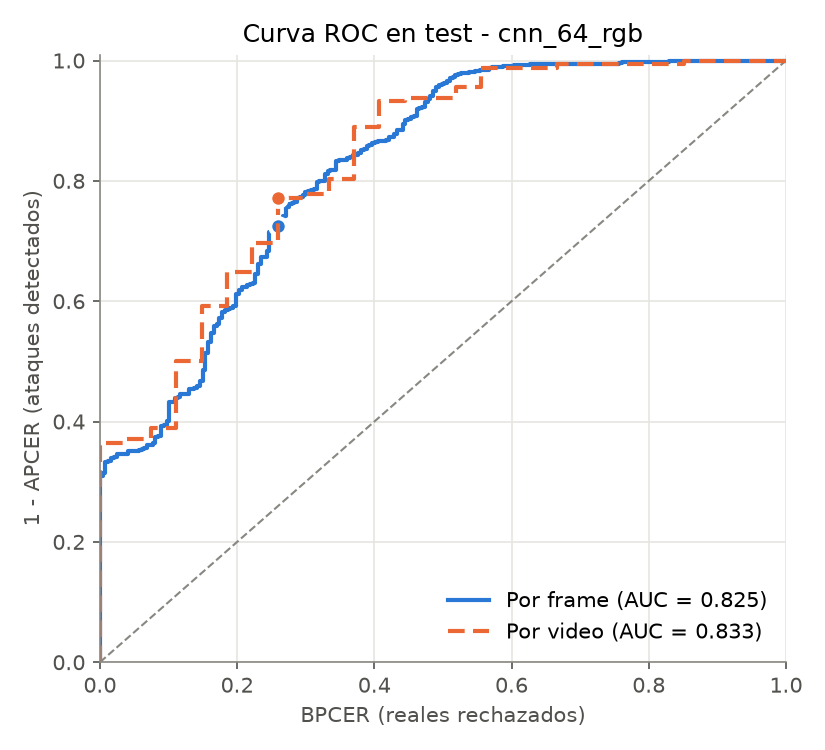

In [7]:
with open(DIR_CNN / "metricas.json", encoding="utf-8") as f:
    metricas = json.load(f)
imprimir_resumen(metricas)
display(Image(DIR_CNN / "matriz_confusion.png", width=650))
display(Image(DIR_CNN / "curva_roc.png", width=420))

## 7. Prueba externa (LCC FASD evaluación)

La misma red, entrenada con LCC, evaluada en el conjunto de evaluación de LCC FASD (normalizado con las
estadísticas de train de LCC). El umbral se sigue eligiendo en la validación de LCC.


=== cnn_64_rgb_test-lcc_eval  (val: lcc, test: lcc_eval) ===
por_frame  umbral=0.507  APCER=0.224  BPCER=0.210  ACER=0.217  exactitud=0.776  AUC=0.843  APCER por tipo={'spoof': 0.224}
por_video  umbral=0.505  APCER=0.223  BPCER=0.210  ACER=0.216  exactitud=0.778  AUC=0.843  APCER por tipo={'spoof': 0.223}


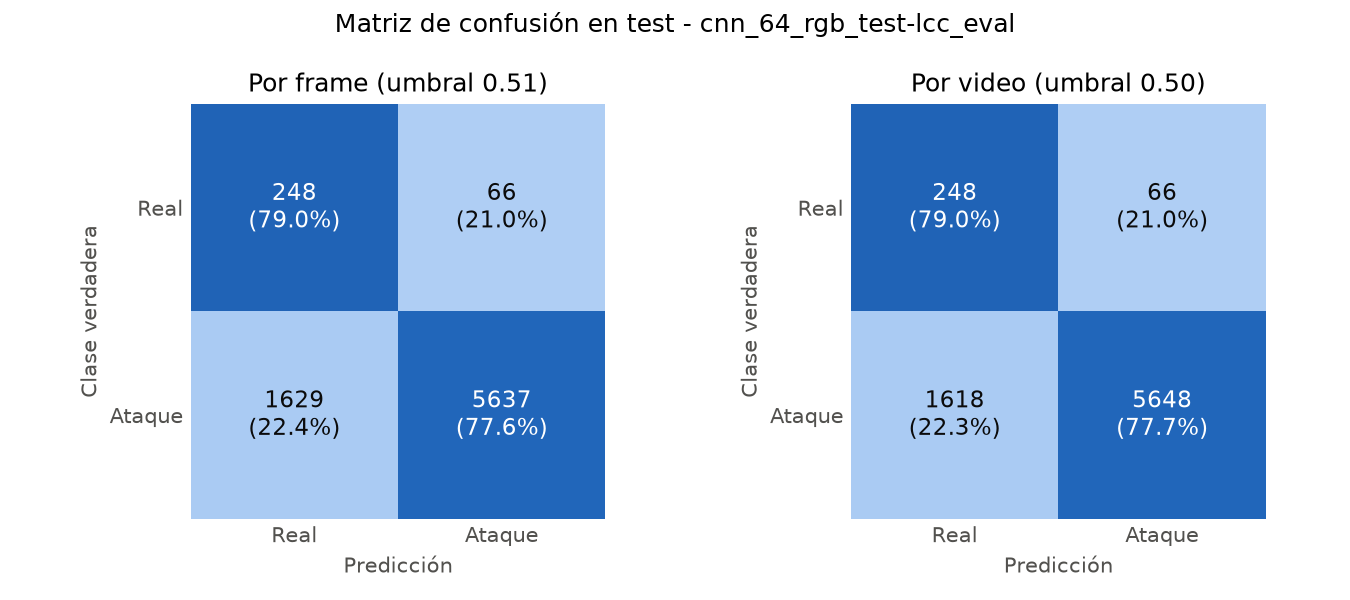

In [8]:
with open(DIR_EVAL / "metricas.json", encoding="utf-8") as f:
    metricas_eval = json.load(f)
imprimir_resumen(metricas_eval)
display(Image(DIR_EVAL / "matriz_confusion.png", width=650))

## 8. Comparación con los modelos de NumPy

Tabla de `results/comparacion_modelos.csv` (la arma `python -m src.evaluate --todos`), filtrada a la mejor
regresión logística y la mejor red feed-forward de `results/mejores_modelos.json` (elegidas por ACER en
**validación**, no en test) y a la CNN, en el test de LCC y en la prueba externa `lcc_eval`.

In [9]:
with open(config.DIR_RESULTS / "mejores_modelos.json", encoding="utf-8") as f:
    mejores = json.load(f)
finales = [mejores["regresion_logistica"]["nombre"], mejores["mlp"]["nombre"], NOMBRE]
carpetas = finales + [f"{n}_test-lcc_eval" for n in finales]

tabla = pd.read_csv(config.DIR_RESULTS / "comparacion_modelos.csv")
tabla = tabla[tabla["modelo"].isin(carpetas)]
columnas = ["modelo", "test", "nivel", "APCER", "BPCER", "ACER", "AUC"]
tabla[columnas].sort_values(["test", "nivel", "ACER"]).round(3).reset_index(drop=True)

,modelo,test,nivel,APCER,BPCER,ACER,AUC
0,cnn_64_rgb,lcc,frame,0.275,0.259,0.267,0.825
1,mlp_256-64_adam_lr0.001_b32_do0.3,lcc,frame,0.388,0.292,0.340,0.691
2,rl_minibatch_lr0.01_b128,lcc,frame,0.475,0.231,0.353,0.630
3,cnn_64_rgb,lcc,video,0.228,0.259,0.244,0.833
4,mlp_256-64_adam_lr0.001_b32_do0.3,lcc,video,0.395,0.259,0.327,0.699
5,rl_minibatch_lr0.01_b128,lcc,video,0.494,0.296,0.395,0.608
6,cnn_64_rgb_test-lcc_eval,lcc_eval,frame,0.224,0.210,0.217,0.843
7,mlp_256-64_adam_lr0.001_b32_do0.3_test-lcc_eval,lcc_eval,frame,0.415,0.312,0.364,0.696
8,rl_minibatch_lr0.01_b128_test-lcc_eval,lcc_eval,frame,0.581,0.268,0.424,0.594
9,cnn_64_rgb_test-lcc_eval,lcc_eval,video,0.223,0.210,0.216,0.843


### Resultados

| Modelo (elegido por validación) | ACER val | ACER frame | AUC frame | ACER video | APCER | BPCER | ACER `lcc_eval` |
|---|---|---|---|---|---|---|---|
| Regresión logística (`rl_minibatch_lr0.01_b128`) | 0.296 | 0.353 | 0.630 | 0.395 | 0.475 | 0.231 | 0.424 |
| Red feed-forward (`mlp_256-64_adam_lr0.001_b32_do0.3`) | 0.293 | 0.340 | 0.691 | 0.327 | 0.388 | 0.292 | 0.364 |
| CNN (`cnn_64_rgb`) | 0.330 | 0.267 | 0.825 | 0.244 | 0.275 | 0.259 | 0.217 |

APCER y BPCER son por frame en el test de LCC.

- En el test de LCC la CNN tiene el menor ACER (0.267 contra 0.340 y 0.353) y sobre todo el mayor AUC (0.83 contra 0.69 y 0.63).
  Entre la regresión logística y la red feed-forward la diferencia por frame es pequeña (0.353 contra 0.340).
- La CNN también es la mejor en la prueba externa `lcc_eval` (ACER 0.217 contra 0.364 y 0.424), aunque ese conjunto tiene solo 314 frames reales.
- En validación la CNN no es mejor: su ACER (0.330) es algo mayor que el de los modelos de NumPy (0.29–0.30). Validación y test
  tienen solo 19 personas cada uno, así que estas cifras varían bastante, y los modelos de NumPy se eligieron entre 53 configuraciones
  justamente por su ACER en validación, mientras que la CNN no se ajustó. La ventaja de la CNN se apoya sobre todo en el AUC y en `lcc_eval`.
- Los tres modelos sobreajustan pronto: la mejor época es la 2 (regresión logística), la 1 (red feed-forward) y la 2 (CNN); después el
  error de train sigue bajando y el de validación sube.